# Final-test figures

These figures read saved test predictions. They do not retrain models or change the frozen threshold. Both use the supplied Latin Modern font, white background, blue/orange palette and PDF/PNG export.


In [3]:
from pathlib import Path
import hashlib
import json
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.font_manager import FontProperties
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/process_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from fashion-demand-ml.")
results_dir = ROOT / "notebooks/closed_test_protocol/results"
metrics_path = results_dir / "final_test_metrics.json"
if not metrics_path.is_file():
    raise FileNotFoundError("Run the final test once before drawing figures.")
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
predictions_path = results_dir / metrics["predictions_file"]
digest = hashlib.sha256()
with predictions_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if digest.hexdigest() != metrics["predictions_sha256"]:
    raise ValueError("Saved predictions changed after final evaluation.")
predictions = pd.read_csv(predictions_path)
if len(predictions) != metrics["test_rows"]:
    raise ValueError("Test row count does not match saved metrics.")

font_path = Path(
    r"C:\Users\irfer\AppData\Local\Microsoft\Windows\Fonts"
    r"\lmroman10-regular.ttf"
)
if not font_path.is_file():
    raise FileNotFoundError(f"Font not found: {font_path}")
font_manager.fontManager.addfont(str(font_path))
fuente = FontProperties(fname=str(font_path))
plt.rcParams.update({"font.family": fuente.get_name(), "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})
BLUE, ORANGE = "#0077B5", "#F5A623"
carpeta = Path(r"C:\Iratxe\UPM\prdl y mllb\imagenes")
formatos = ["pdf", "png"]

def save_figure(fig, nombre):
    carpeta.mkdir(parents=True, exist_ok=True)
    for formato in formatos:
        ruta = carpeta / f"{nombre}.{formato}"
        fig.savefig(ruta, format=formato, dpi=300, facecolor="white",
                    transparent=False, bbox_inches="tight")
        print(f"Saved: {ruta}")
    plt.show()


## Regression error by observed sales

The selected model and baseline use exactly the same test rows. This grouping is descriptive and does not influence model selection.


,model_MAE,persistence_MAE,n
segment,,,
0,0.834,1.687,63022
1–5,1.821,2.222,110715
6–20,5.300,6.385,66492
>20,26.754,30.356,49261


Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\final_test_regression_error_by_sales.pdf
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\final_test_regression_error_by_sales.png


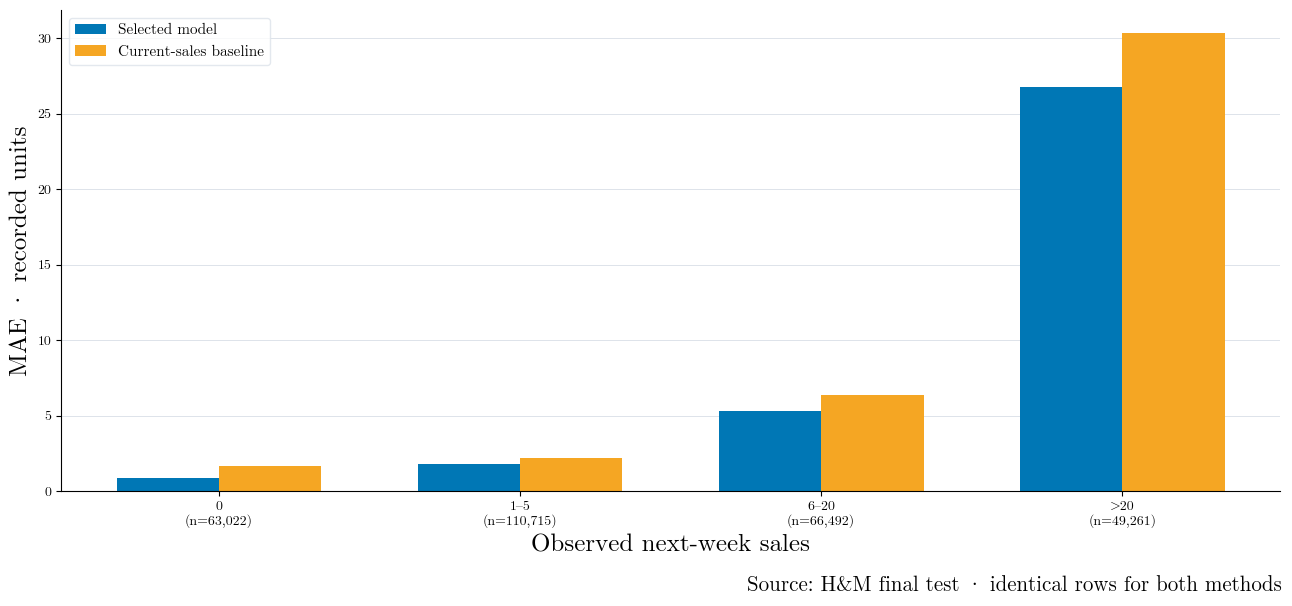

In [ ]:
actual = predictions["actual_next_week_sales"]
model_error = (actual - predictions["predicted_next_week_sales"]).abs()
baseline_error = (actual - predictions["persistence_prediction"]).abs()
segments = pd.cut(actual, bins=[-0.1, 0, 5, 20, np.inf],
                  labels=["0", "1–5", "6–20", ">20"])
table = pd.DataFrame({"segment": segments, "model_error": model_error,
                      "baseline_error": baseline_error}).groupby(
    "segment", observed=False
).agg(model_MAE=("model_error", "mean"),
      persistence_MAE=("baseline_error", "mean"), n=("model_error", "size"))
display(table.round(3))

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(table))
width = .34
ax.bar(x-width/2, table["model_MAE"], width, color=BLUE, label="Selected model")
ax.bar(x+width/2, table["persistence_MAE"], width, color=ORANGE,
       label="Current-sales baseline")
ax.set_xticks(x, [f"{label}\n(n={n:,})" for label,n in zip(table.index,table["n"])])
ax.set_xlabel("Observed next-week sales", fontproperties=fuente,
              fontweight="bold", fontsize=18)
ax.set_ylabel("MAE · recorded units", fontproperties=fuente,
              fontweight="bold", fontsize=18)
ax.grid(axis="y", color="#DDE3EA", linewidth=.7)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=True, facecolor="white", edgecolor="#DDE3EA",
          prop=FontProperties(fname=str(font_path),size=17))
fig.text(.99,.005,"Source: H&M final test · identical rows for both methods",
         ha="right",fontproperties=fuente,fontsize=15)
fig.tight_layout(rect=[0,.04,1,1])
save_figure(fig,"final_test_regression_error_by_sales")


## Classification confusion matrix

Blue boxes are correct decisions; orange boxes are mistakes. The threshold was fixed during development.


,Predicted not high,Predicted high
Actually not high,213644,14645
Actually high,9705,51496


Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\final_test_classification_confusion.pdf
Saved: C:\Iratxe\UPM\prdl y mllb\imagenes\final_test_classification_confusion.png


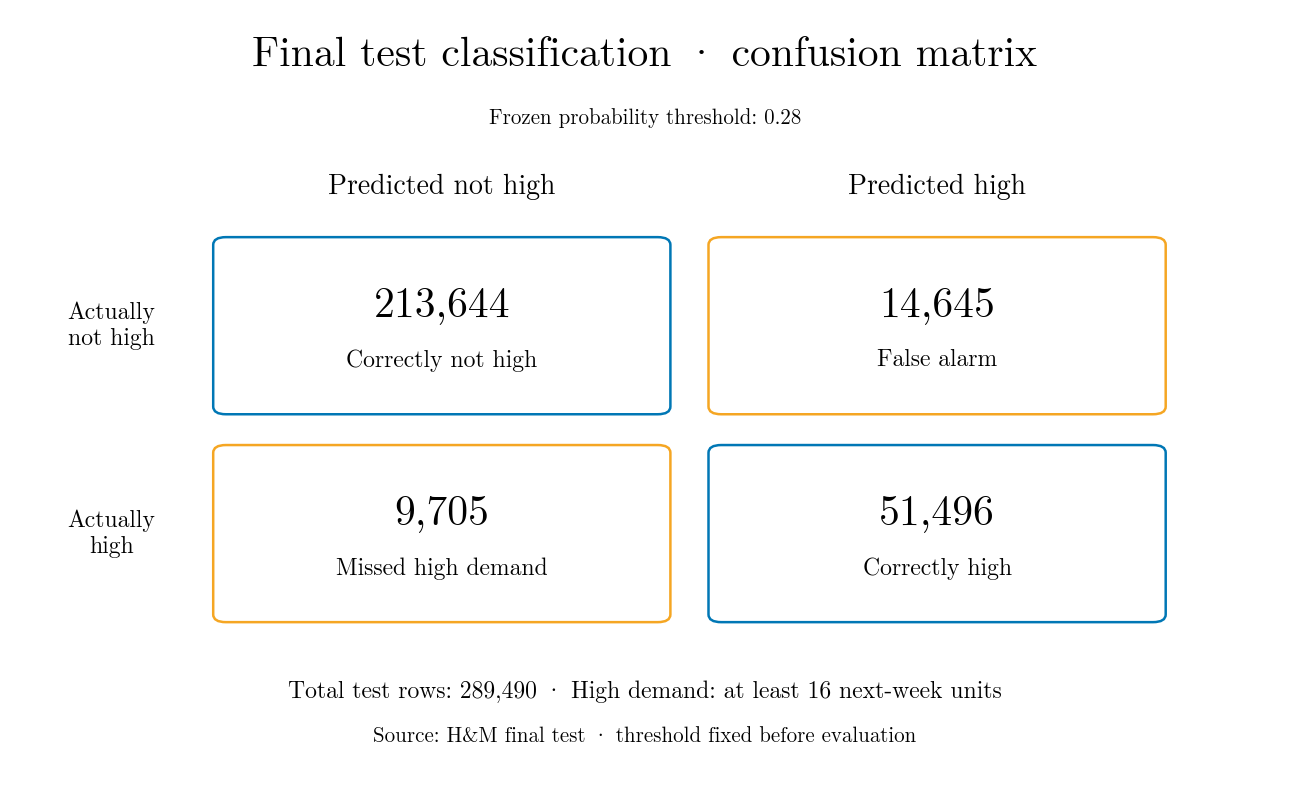

In [5]:
actual = predictions["actual_high_demand"].astype(int).to_numpy()
cut = float(metrics["frozen_decision"]["probability_threshold"])
predicted = predictions["predicted_high_demand_probability"].to_numpy() >= cut
tn = int(((actual==0)&~predicted).sum())
fp = int(((actual==0)&predicted).sum())
fn = int(((actual==1)&~predicted).sum())
tp = int(((actual==1)&predicted).sum())
assert tn+fp+fn+tp == len(predictions)
display(pd.DataFrame([[tn,fp],[fn,tp]],
                     index=["Actually not high","Actually high"],
                     columns=["Predicted not high","Predicted high"]))
fig,ax=plt.subplots(figsize=(13,8))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis("off")
def texto(x,y,contenido,size=15,**kwargs):
    ax.text(x,y,contenido,ha="center",va="center",fontproperties=fuente,
            fontsize=size,color="black",transform=ax.transAxes,**kwargs)
def caja(x,y,count,label,color):
    forma=FancyBboxPatch((x-.17,y-.105),.34,.21,boxstyle="round,pad=0.01",
                         facecolor="white",edgecolor=color,linewidth=1.8,
                         transform=ax.transAxes)
    ax.add_patch(forma)
    texto(x,y+.025,f"{count:,}",size=30)
    texto(x,y-.045,label,size=17)
texto(.5,.94,"Final test classification · confusion matrix",size=30)
texto(.5,.86,f"Frozen probability threshold: {cut:.2f}",size=15)
texto(.34,.77,"Predicted not high",size=20)
texto(.73,.77,"Predicted high",size=20)
texto(.08,.59,"Actually\nnot high",size=17)
texto(.08,.32,"Actually\nhigh",size=17)
caja(.34,.59,tn,"Correctly not high",BLUE)
caja(.73,.59,fp,"False alarm",ORANGE)
caja(.34,.32,fn,"Missed high demand",ORANGE)
caja(.73,.32,tp,"Correctly high",BLUE)
texto(.5,.115,f"Total test rows: {len(predictions):,} · High demand: at least {metrics['high_demand_units_threshold']} next-week units",size=17)
texto(.5,.055,"Source: H&M final test · threshold fixed before evaluation",size=15)
fig.tight_layout()
save_figure(fig,"final_test_classification_confusion")
